In [2]:

import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from saber11.config import load_config
from saber11.data.repository import read_raw

# El notebook corre dentro de notebooks/; las rutas del proyecto son desde la raíz.
if Path.cwd().name == "notebooks":
    os.chdir("..")

raw = read_raw(load_config())
raw.head()


,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,TI,SB11202240002331,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,Si,Si,Si,A1,56,51,52,46,59,262
1,20224,TI,SB11202240002331,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,Si,Si,Si,A1,56,51,52,46,59,262
2,20224,TI,SB11202240002335,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,No,No,Si,A1,48,51,49,46,45,239
3,20224,TI,SB11202240002335,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,No,No,Si,A1,48,51,49,46,45,239
4,20224,TI,SB11202240002340,URBANO,N,A,ACADÉMICO,111001076376,111001076376,11,...,No,No,Si,A-,42,45,34,39,55,216


**Interpretación:** Cada fila es un estudiante que presentó el Saber 11 en el periodo 20224 (2022, segundo calendario). Las columnas hablan del colegio (`cole_*`), de la familia (`fami_*`) y de los resultados (`punt_*` y `desemp_ingles`).

Lo que más me llamó la atención es que hay registros repetidos: las filas 0 y 1 tienen el mismo `estu_consecutivo` (SB11202240002331) y los mismos puntajes, y pasa igual con las filas 2 y 3. Como ese código identifica a cada estudiante, significa que algunos aparecen dos veces, y si no los quito van a pesar doble en los promedios.

Además, los puntajes son numéricos y `desemp_ingles` y las columnas Si/No son categóricas, así que las voy a analizar distinto. Con solo 5 filas no puedo concluir nada de toda la población, por eso mi siguiente paso es contar cuántos duplicados hay y eliminarlos.

In [3]:
print("Filas y columnas:", raw.shape)
nulos = raw.isna().mean().sort_values(ascending=False)
nulos[nulos > 0].round(3)

Filas y columnas: (152584, 51)


cole_bilingue           0.185
cole_caracter           0.046
fami_estratovivienda    0.043
fami_tieneinternet      0.041
fami_educacionpadre     0.040
fami_educacionmadre     0.040
fami_tieneautomovil     0.028
fami_cuartoshogar       0.028
fami_tienelavadora      0.027
fami_tienecomputador    0.027
fami_personashogar      0.027
desemp_ingles           0.000
punt_ingles             0.000
dtype: float64

**Interpretación:** El dataset tiene 152.584 filas y 51 columnas. Solo 12 columnas tienen valores nulos, y en casi todas el porcentaje es bajo (entre 2,7 % y 4,6 %), así que no parece un problema grave de calidad.

La excepción es `cole_bilingue`, con 18,5 % de nulos, que es bastante más que las demás. Antes de usarla tendría que decidir si imputo esos valores, los trato como una categoría aparte ("sin dato") o la dejo fuera.

Las columnas de familia (`fami_*`) tienen entre 2,7 % y 4,3 % de nulos, y varias están muy parecidas (por ejemplo `fami_tienecomputador`, `fami_tienelavadora` y `fami_personashogar` con 2,7 %). Eso me hace pensar que probablemente son los mismos estudiantes que no respondieron esa parte del cuestionario. Esto es una sospecha mía, todavía no la he verificado.

Lo bueno es que `punt_ingles` y `desemp_ingles` aparecen con 0,000 después de redondear, o sea que casi no tienen nulos, y las demás columnas de puntajes no aparecen en la lista, es decir, no tienen nulos. Eso significa que la variable principal del análisis está completa.

Por eso, mi plan es imputar o marcar los nulos de las columnas `fami_*` y decidir con más cuidado qué hacer con `cole_bilingue`.

In [4]:
print("Filas:", len(raw))
print("Estudiantes únicos:", raw["estu_consecutivo"].nunique())
print("Filas idénticas repetidas:", raw.duplicated().sum())

Filas: 152584
Estudiantes únicos: 76253
Filas idénticas repetidas: 76331


**Interpretación:** El dataset tiene 152.584 filas, pero solo 76.253 estudiantes únicos, o sea casi el doble de filas que de estudiantes. Además, hay 76.331 filas idénticas repetidas. Esto confirma lo que vi en las primeras filas: cada estudiante aparece dos veces con exactamente los mismos datos.

Hice la cuenta: 152.584 − 76.253 = 76.331, que es justo el número de filas repetidas. Eso quiere decir que todo el exceso se explica por duplicados exactos y que no hay un mismo estudiante con registros distintos.

Esto significa que si no los quito, los conteos, promedios y gráficos quedarían inflados porque cada estudiante pesaría doble. Por eso mi siguiente paso es eliminar los duplicados con `drop_duplicates()` y comprobar que queden 76.253 filas, una por estudiante.

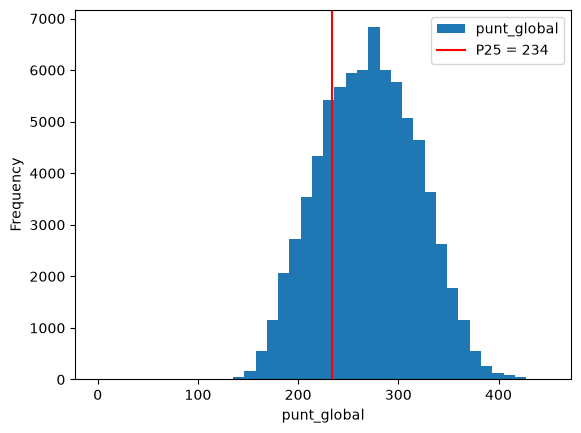

Umbral P25: 234.0


In [5]:
TARGET = "riesgo_bajo_desempeno"

df = raw.drop_duplicates(subset="estu_consecutivo").copy()
df["punt_global"] = pd.to_numeric(df["punt_global"], errors="coerce")
umbral = df["punt_global"].quantile(0.25)
df[TARGET] = (df["punt_global"] < umbral).astype(int)

ax = df["punt_global"].plot.hist(bins=40)
ax.axvline(umbral, color="red", label=f"P25 = {umbral:.0f}")
ax.set_xlabel("punt_global")
ax.legend()
plt.savefig("reports/figures/eda_punt_global.png", dpi=120, bbox_inches="tight")
plt.show()
print("Umbral P25:", umbral)

**Interpretación:** El histograma de `punt_global` tiene forma de campana y es bastante simétrico. La mayoría de estudiantes saca entre 200 y 350 puntos, con el pico cerca de 270, y casi nadie baja de 150 ni pasa de 400. Los datos se ven normales, sin nada raro que me haga dudar de ellos.

La línea roja es el percentil 25, que cae en 234 puntos. Quien queda a la izquierda de esa línea hace parte del 25 % con los puntajes más bajos, y a esos estudiantes los marco como `riesgo_bajo_desempeno = 1`. Todos los demás quedan en 0.

Como el umbral sale de la propia distribución, el target queda con cerca de 25 % en riesgo y 75 % sin riesgo. Es un desbalance moderado, y por eso más adelante no me voy a fiar solo de la accuracy para evaluar el modelo.

In [7]:
df[TARGET].value_counts(normalize=True).round(4)

riesgo_bajo_desempeno
0    0.7543
1    0.2457
Name: proportion, dtype: float64

**Interpretación:** El 75,43 % de los estudiantes quedó en la clase 0 (sin riesgo) y el 24,57 % en la clase 1 (en riesgo). Tiene sentido, porque el umbral es el percentil 25, así que esperaba algo cercano a 25 %. Hay como tres estudiantes sin riesgo por cada uno en riesgo.

Esto es importante porque un modelo que siempre responda "0" acertaría el 75 % de las veces sin haber aprendido nada. En el papel se vería bien, pero en la práctica no serviría: no detectaría a ni un solo estudiante en riesgo, que es justo a quienes quiero encontrar.

Por eso no me voy a fiar solo de la accuracy. Mi modelo tiene que superar ese 0,75 y, además, mirar qué tan bien identifica la clase 1 con métricas como recall, precision y F1.